# Comparative Analysis of Quality of Life Indicators
**CIS 9650 Group Project**

## 1. Project Overview
This project analyzes key quality of life indicators to compare **New York City**, **Boston**, and **San Francisco**. We use aggregated data from the US Census Bureau from [DataUSA](https://https://datausa.io/), City Open Data portals, and Zillow to identify trade-offs between these major metropolitan areas.

## 2. Research Questions
In accordance with the project requirements, we aim to answer the following 5 questions:
1.  **Commuting:** How do the primary modes of transportation differ between these three cities?
2.  **Health:** How does the availability of health insurance coverage compare across these populations?
3.  **Economy (Income):** How does median household income vary between NYC, Boston, and San Francisco?
4.  **Economy (Housing):** How do housing costs compare relative to income (affordability) in these regions?
5.  **Education:** Which city has the highest population with a Bachelor's degree or higher?

In [1]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 12/10/25 20:55:30


In [2]:
#Global Configuration and Imports
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from google.colab import drive
import os

## 3. Commuting Analysis
**Objective:** Transportation is a critical component of urban life. In this section, we compare how residents in NYC, Boston, and San Francisco commute to work. We analyze the share of residents using public transit, driving, or walking, and examine how these choices reflect the infrastructure of each city. Then, we compare the average commute time in the three cities by analyzing the share of residents with respect to their commute time.

In [3]:


drive.mount('/content/drive', force_remount=True)
os.listdir("/content/drive/My Drive/CIS_9650_Group_Project")


Mounted at /content/drive


['Deliverables',
 'CIS 9650 Project Instructions Fall 2025.pdf',
 'Team charter.gdoc',
 'Project Proposal - Submission Ready.gdoc',
 'Dataset Description.docx',
 'Databases',
 'employee_earnings_report_2024.csv',
 'HousingDB_post2010.xlsx',
 'fy2025-property-assessment-data_12_30_2024.csv',
 'Citywide_Payroll_Data_(Fiscal_Year)_20251029.csv',
 'tmp_xixuq_l.csv',
 'Meeting Notes - Submission Ready.gdoc',
 'Progress Report',
 'Income vs Housing',
 'Deadlines Requirements Tasks.gdoc',
 'Health Insurance Comparison',
 'Health Insurance Comparison-20251206T054734Z-1-001.zip',
 'Commuting',
 'Meeting Notes_Draft.docx',
 'Meeting Notes - Template.gdoc']

LOADING DATA FOR MEANS OF COMMUTING COMPARISON



In [4]:
#Read the data files into the data frame
df_NYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Means_of_Commuting_Comparison/Commuter_Transportation_NYC.csv")
df_SF = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Means_of_Commuting_Comparison/Commuter_Transportation_SF.csv")
df_BOS = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Means_of_Commuting_Comparison/Commuter_Transportation_BOS.csv")

In [5]:
# Display the dataframe shape
print ("NYC DATA SHAPE", df_NYC.shape)
print ("SF DATA SHAPE",df_SF.shape)
print ("BOS DATA SHAPE",df_BOS.shape)

NYC DATA SHAPE (99, 6)
SF DATA SHAPE (99, 6)
BOS DATA SHAPE (99, 6)


In [6]:
# Display SF's sample data
df_SF.sample(5)

,Group ID,Group,Year,Commute Means,Commute Means Moe,share
47,4,Motorcycle,2016,4435,575.00000,0.009256
75,6,Walked,2022,51322,1985.00000,0.105270
17,1,Carpooled,2019,35546,1600.94191,0.069364
49,4,Motorcycle,2018,4591,472.00000,0.009103
50,4,Motorcycle,2019,4526,586.00000,0.008832


In [7]:
# Display Boston's sample data
df_BOS.sample(5)

,Group ID,Group,Year,Commute Means,Commute Means Moe,share
10,0,Drove Alone,2023,126122,3097.000000,0.340844
90,8,Worked At Home,2015,12155,827.000000,0.035842
15,1,Carpooled,2017,20590,1153.906842,0.057650
2,0,Drove Alone,2015,130984,2171.000000,0.386235
76,6,Walked,2023,50923,1934.000000,0.137619


In [8]:
# Need data from all three datasets - Combining them first without contaminating the data by creating a column indicating where it came from as well
import glob
path = "/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Means_of_Commuting_Comparison/*.csv"
files = glob.glob(path)
# Reading each CSV and adding a source column
all_data = []
for f in files:
  df= pd.read_csv(f)
  df["source_file"] = os.path.basename(f)
  all_data.append(df)
# Combining into one data frame
combined_df = pd.concat(all_data, ignore_index=True)

combined_df.sample(10)

,Group ID,Group,Year,Commute Means,Commute Means Moe,share,source_file
202,0,Drove Alone,2017,170042,2407.000000,0.343301,Commuter_Transportation_SF.csv
36,3,Taxi,2016,37630,1627.000000,0.009652,Commuter_Transportation_NYC.csv
174,6,Walked,2022,50987,1626.000000,0.140253,Commuter_Transportation_BOS.csv
185,7,Other,2022,4752,584.000000,0.013072,Commuter_Transportation_BOS.csv
126,2,Public Transit,2018,121524,2643.012486,0.334314,Commuter_Transportation_BOS.csv
187,8,Worked At Home,2013,11837,848.000000,0.036695,Commuter_Transportation_BOS.csv
207,0,Drove Alone,2022,139890,3115.000000,0.286939,Commuter_Transportation_SF.csv
70,6,Walked,2017,396134,5711.000000,0.099653,Commuter_Transportation_NYC.csv
89,8,Worked At Home,2014,151357,2981.000000,0.040250,Commuter_Transportation_NYC.csv
208,0,Drove Alone,2023,135910,2844.000000,0.286332,Commuter_Transportation_SF.csv


In [9]:
# Create a column showing which city the data in each row refers on the dataframe given
def label(column):
  if column["source_file"] == "Commuter_Transportation_NYC.csv":
    return "NYC"
  elif column["source_file"] == "Commuter_Transportation_SF.csv":
    return "SF"
  elif column["source_file"] == "Commuter_Transportation_BOS.csv":
    return "BOS"
  else:
    return "Unknown"
combined_df["city"] = combined_df.apply(label, axis=1)
combined_df.sample(15)

,Group ID,Group,Year,Commute Means,Commute Means Moe,share,source_file,city
63,5,Bicycle,2021,54919,2053.000000,0.013581,Commuter_Transportation_NYC.csv,NYC
64,5,Bicycle,2022,58514,2142.000000,0.014659,Commuter_Transportation_NYC.csv,NYC
16,1,Carpooled,2018,177245,3528.761539,0.044832,Commuter_Transportation_NYC.csv,NYC
214,1,Carpooled,2018,36661,1611.884921,0.072688,Commuter_Transportation_SF.csv,SF
81,7,Other,2017,21895,1282.000000,0.005508,Commuter_Transportation_NYC.csv,NYC
66,6,Walked,2013,377698,4972.000000,0.102073,Commuter_Transportation_NYC.csv,NYC
54,4,Motorcycle,2023,3581,599.000000,0.000905,Commuter_Transportation_NYC.csv,NYC
287,8,Worked At Home,2014,32233,1423.000000,0.070583,Commuter_Transportation_SF.csv,SF
162,5,Bicycle,2021,7294,648.000000,0.019943,Commuter_Transportation_BOS.csv,BOS
184,7,Other,2021,4524,531.000000,0.012369,Commuter_Transportation_BOS.csv,BOS


In [10]:
# Display data values using the dataframe for a specific year - testing
filtered_2023 = combined_df[combined_df["Year"] == 2023]
filtered_2023.sample(20)

,Group ID,Group,Year,Commute Means,Commute Means Moe,share,source_file,city
153,4,Motorcycle,2023,171,111.000000,0.000462,Commuter_Transportation_BOS.csv,BOS
76,6,Walked,2023,371440,6088.000000,0.093918,Commuter_Transportation_NYC.csv,NYC
54,4,Motorcycle,2023,3581,599.000000,0.000905,Commuter_Transportation_NYC.csv,NYC
142,3,Taxi,2023,1942,363.000000,0.005248,Commuter_Transportation_BOS.csv,BOS
21,1,Carpooled,2023,168561,4402.871563,0.042620,Commuter_Transportation_NYC.csv,NYC
241,3,Taxi,2023,3707,578.000000,0.007810,Commuter_Transportation_SF.csv,SF
175,6,Walked,2023,50923,1934.000000,0.137619,Commuter_Transportation_BOS.csv,BOS
43,3,Taxi,2023,45653,2196.000000,0.011543,Commuter_Transportation_NYC.csv,NYC
274,6,Walked,2023,47281,1938.000000,0.099610,Commuter_Transportation_SF.csv,SF
285,7,Other,2023,9081,770.000000,0.019132,Commuter_Transportation_SF.csv,SF


In [11]:
'''
Use the dataframe printed above to plot using share/percentage
The goal is to plot the different means of transportation in the x axis and the percentage/share of residents in the y axis. By plotting grouped bars (representing each city),
we can easily compare how the percentage of residents who use the differenttransportation method varies in the different cities.
'''
# Creating a pivoted data frame
pivot_df =filtered_2023.pivot(index ="Group", columns = "city", values = "share")
pivot_df.sample(len(pivot_df.index))

city,BOS,NYC,SF
Group,,,
Worked At Home,0.187769,0.150284,0.274570
Motorcycle,0.000462,0.000905,0.005507
Bicycle,0.021498,0.015125,0.032880
Carpooled,0.053650,0.042620,0.059915
Taxi,0.005248,0.011543,0.007810
Drove Alone,0.340844,0.219296,0.286332
Walked,0.137619,0.093918,0.099610
Public Transit,0.240297,0.455549,0.214244
Other,0.012613,0.010758,0.019132


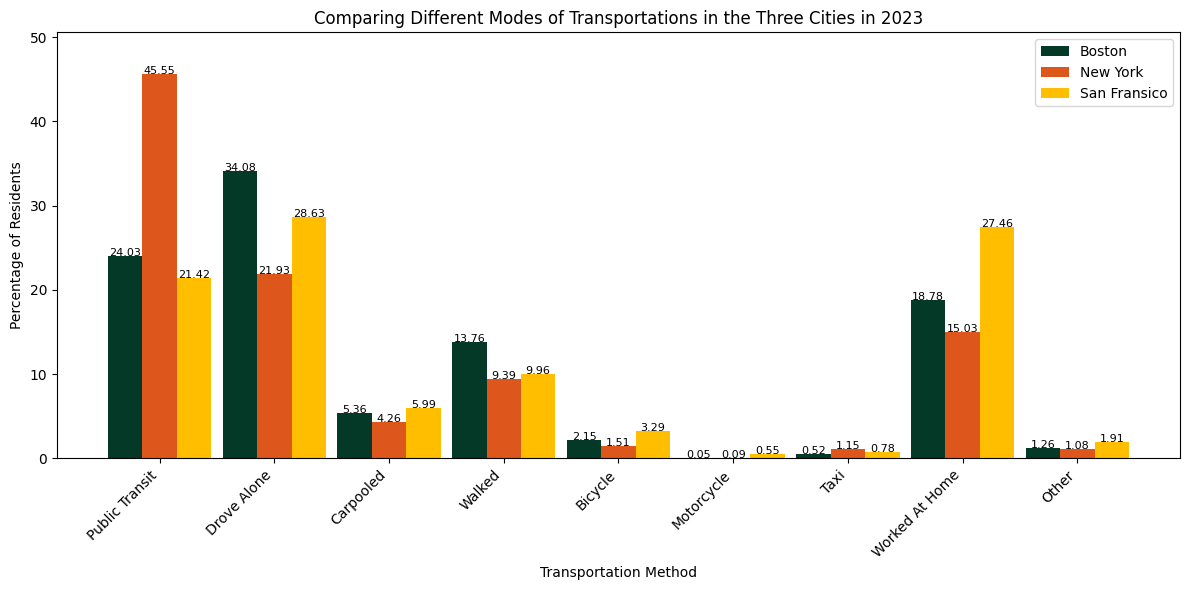

In [12]:
# Creating a pivoted data frame
pivot_df =filtered_2023.pivot(index ="Group", columns = "city", values = "share")
pivot_df.sample(len(pivot_df.index))
# Changing the number of shares to percentages on the y axis to allow more readability
pivot_df = pivot_df * 100

# Customizing the order of the means of transportation so that Worked at home and other appear last
custom_order =["Public Transit", "Drove Alone", "Carpooled", "Walked", "Bicycle","Motorcycle","Taxi","Worked At Home","Other"]
pivot_df = pivot_df.reindex(custom_order)
#Plotting the data frame above starting from x axis
x = np.arange(len(pivot_df.index))
width = 0.30
plt.figure(figsize=(12, 6))
plt.ylim(0, pivot_df.max().max() + 5)

# Colored bars for each city
colors = ["#DD571C", "#043927", "#FFBF00"]
plt.bar(x - width, pivot_df["BOS"], width, label="Boston", color = colors[1])
plt.bar(x,         pivot_df["NYC"], width, label="New York", color = colors[0])
plt.bar(x + width, pivot_df["SF"],  width, label="San Fransico", color = colors[2])
plt.xticks(x, pivot_df.index, rotation=45, ha="right")
# Showing the percentage on top of the bar for more readability
for i, city in enumerate(pivot_df.columns):
    for x_pos, val in enumerate(pivot_df[city]):
        plt.text(
            x_pos + (i-1)*0.3,   # bar position
            val + 0.005,          # slightly above bar
            f"{val:.2f}",         # formatted value
            ha="center", fontsize=8
        )
#Labels
plt.xlabel("Transportation Method")
plt.ylabel("Percentage of Residents")
plt.title("Comparing Different Modes of Transportations in the Three Cities in 2023")
plt.legend()

plt.tight_layout()
plt.show()




LOADING DATA FOR AVERAGE TIME COMPARISON

In [13]:
os.listdir("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Average_commute_time_comparison")

['Commute_Time_NYC.csv',
 'Commute_Time_SF.gsheet',
 'Commute_Time_NYC.gsheet',
 'Average_commute_time_data_analysis.ipynb',
 'Commute_Time_BOS.csv',
 'Commute_Time_SF.csv']

In [14]:
#Read the data files into the data frame
df_NYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Average_commute_time_comparison/Commute_Time_NYC.csv")
df_SF = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Average_commute_time_comparison/Commute_Time_SF.csv")
df_BOS = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Commuting/Average_commute_time_comparison/Commute_Time_BOS.csv")

In [15]:
# Display the dataframe shape
print ("NYC DATA SHAPE", df_NYC.shape)
print ("SF DATA SHAPE",df_SF.shape)
print ("BOS DATA SHAPE",df_BOS.shape)

NYC DATA SHAPE (264, 8)
SF DATA SHAPE (264, 8)
BOS DATA SHAPE (264, 8)


In [16]:
#Checking if all datasets align
# Display NYC's sample data
df_NYC.sample(5)

,Travel Time ID,Travel Time,Year,Commuter Population,Commuter Population Moe,Place,Place ID,share
174,3,15-19 Minutes,2022,251409,5165.0,"New York, NY",16000US3651000,0.072432
238,9,45-59 Minutes,2020,592085,6926.0,"New York, NY",16000US3651000,0.162938
183,4,20-24 Minutes,2020,327450,5446.0,"New York, NY",16000US3651000,0.090112
41,3,15-19 Minutes,2021,21368336,38140.0,United States,01000US,0.152388
50,4,20-24 Minutes,2019,20782840,38755.0,United States,01000US,0.143491


In [17]:
# Display SF's sample data
df_SF.sample(5)

,Travel Time ID,Travel Time,Year,Commuter Population,Commuter Population Moe,Place,Place ID,share
84,7,35-39 Minutes,2020,4444652,24527.0,United States,01000US,0.031188
24,2,10-14 Minutes,2015,19178644,31305.0,United States,01000US,0.139716
74,6,30-34 Minutes,2021,19260932,36830.0,United States,01000US,0.137359
254,11,90+ Minutes,2014,10152,760.0,"San Francisco, CA",16000US0667000,0.023919
159,2,10-14 Minutes,2018,35021,1539.0,"San Francisco, CA",16000US0667000,0.074311


In [18]:
# Display Boston's sample data
df_BOS.sample(5)

,Travel Time ID,Travel Time,Year,Commuter Population,Commuter Population Moe,Place,Place ID,share
65,5,25-29 Minutes,2023,9324180,35830.0,United States,01000US,0.068370
81,7,35-39 Minutes,2017,4158159,21253.0,United States,01000US,0.029406
216,7,35-39 Minutes,2020,14282,965.0,"Boston, MA",16000US2507000,0.040999
130,11,90+ Minutes,2022,3887726,20907.0,United States,01000US,0.028093
77,7,35-39 Minutes,2013,3673571,17953.0,United States,01000US,0.027468


In [19]:
#Need the data from each dataset - We combine all three dataframes and delete duplicates
combined_df = pd.concat([df_BOS, df_NYC,df_SF], ignore_index=True)
combined_df = combined_df.drop_duplicates()
combined_df.sample(20)


,Travel Time ID,Travel Time,Year,Commuter Population,Commuter Population Moe,Place,Place ID,share
212,7,35-39 Minutes,2016,12209,825.0,"Boston, MA",16000US2507000,0.036342
484,8,40-44 Minutes,2013,236545,3911.0,"New York, NY",16000US3651000,0.066582
173,3,15-19 Minutes,2021,39019,1826.0,"Boston, MA",16000US2507000,0.121644
466,6,30-34 Minutes,2017,642506,6261.0,"New York, NY",16000US3651000,0.168522
488,8,40-44 Minutes,2017,272351,4255.0,"New York, NY",16000US3651000,0.071435
714,4,20-24 Minutes,2023,51009,1966.0,"San Francisco, CA",16000US0667000,0.148139
525,11,90+ Minutes,2021,275534,5064.0,"New York, NY",16000US3651000,0.076261
413,1,5-9 Minutes,2019,111421,2985.0,"New York, NY",16000US3651000,0.029253
423,2,10-14 Minutes,2018,198553,3387.0,"New York, NY",16000US3651000,0.052403
156,2,10-14 Minutes,2015,29032,1267.0,"Boston, MA",16000US2507000,0.088790


In [20]:
# Check if merging is done properly
# Checking US data from each dataframes and comparing them to the combined DF
df_US_From_Bos = df_BOS[df_BOS["Place"]== "United States"]
print("US data from Boston DF",df_US_From_Bos.shape)
df_US_From_NYC = df_BOS[df_NYC["Place"]== "United States"]
print("US data from NYC DF",df_US_From_Bos.shape)
df_US_From_SF = df_BOS[df_SF["Place"]== "United States"]
print("US data from SF DF",df_US_From_Bos.shape)
df_US_From_Combined = combined_df[combined_df["Place"]== "United States"]
print("US data from Combined DF",df_US_From_Combined.shape)

US data from Boston DF (132, 8)
US data from NYC DF (132, 8)
US data from SF DF (132, 8)
US data from Combined DF (132, 8)


In [21]:
# We are going to use the 2023 data for comparison
combined_df_2023 = combined_df[combined_df["Year"]== 2023]
combined_df_2023.sample(20)

,Travel Time ID,Travel Time,Year,Commuter Population,Commuter Population Moe,Place,Place ID,share
10,0,< 5 Minutes,2023,4083661,20316.0,United States,01000US,0.029944
65,5,25-29 Minutes,2023,9324180,35830.0,United States,01000US,0.068370
670,0,< 5 Minutes,2023,4805,548.0,"San Francisco, CA",16000US0667000,0.013955
505,9,45-59 Minutes,2023,541297,6353.0,"New York, NY",16000US3651000,0.161073
483,7,35-39 Minutes,2023,122989,3059.0,"New York, NY",16000US3651000,0.036598
131,11,90+ Minutes,2023,3785340,21431.0,United States,01000US,0.027756
417,1,5-9 Minutes,2023,101667,3113.0,"New York, NY",16000US3651000,0.030253
87,7,35-39 Minutes,2023,4380226,22803.0,United States,01000US,0.032118
98,8,40-44 Minutes,2023,5356236,23648.0,United States,01000US,0.039275
527,11,90+ Minutes,2023,239061,4396.0,"New York, NY",16000US3651000,0.071137


In [22]:
# Creating a pivoted DF showing the cities and the US and the travel time range along with the share of Residents
pivot_df =combined_df_2023.pivot(index ="Travel Time", columns = "Place", values = "share")
pivot_df.sample(len(pivot_df.index))

Place,"Boston, MA","New York, NY","San Francisco, CA",United States
Travel Time,,,,
15-19 Minutes,0.131925,0.073605,0.131707,0.153188
10-14 Minutes,0.081205,0.053209,0.079894,0.132654
20-24 Minutes,0.134903,0.092731,0.148139,0.143349
5-9 Minutes,0.049686,0.030253,0.039052,0.096232
40-44 Minutes,0.058357,0.070961,0.055914,0.039275
60-89 Minutes,0.085617,0.186888,0.089155,0.059630
35-39 Minutes,0.039192,0.036598,0.038878,0.032118
30-34 Minutes,0.190944,0.162660,0.192814,0.136931
90+ Minutes,0.022971,0.071137,0.031394,0.027756


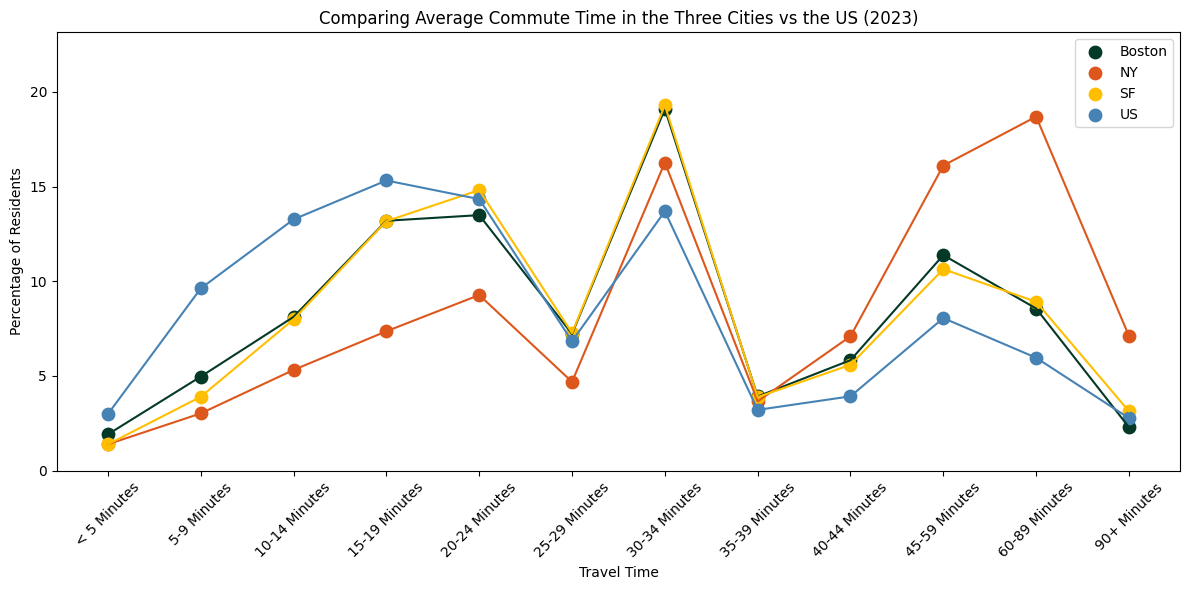

In [23]:
# Creating a pivoted DF showing the cities and the US and the travel time range along with the share of Residents
pivot_df=combined_df_2023.pivot(index ="Travel Time", columns = "Place", values = "share")
pivot_df= pivot_df* 100
#pivot_df.sample(len(pivot_df.index))

# Customizing the order of the index (Travel time) for convenience/readability

custom_order = ['< 5 Minutes','5-9 Minutes','10-14 Minutes','15-19 Minutes','20-24 Minutes','25-29 Minutes','30-34 Minutes','35-39 Minutes',
                   '40-44 Minutes','45-59 Minutes','60-89 Minutes','90+ Minutes']
pivot_df = pivot_df.reindex(custom_order)

# Plotting - scatter plots
#The x axis will be the travel time and the y axis will be the share of residents
x = pivot_df.index

plt.figure(figsize=(12,6))

# Scatter for each city and US
plt.scatter(x, pivot_df["Boston, MA"], label="Boston", s=80,color = "#043927" )
plt.scatter(x, pivot_df["New York, NY"], label="NY", s=80,color = "#DD571C")
plt.scatter(x, pivot_df["San Francisco, CA"], label="SF", s=80,color ="#FFBF00")
plt.scatter(x, pivot_df["United States"], label="US", s=80, color = "#4682B4")

#Expanding the y axis
ymax = pivot_df.max().max()
plt.ylim(0, ymax * 1.2)

plt.xticks(rotation=45)
# Connecting the scatterplot with a line
plt.plot(x, pivot_df["Boston, MA"], color="#043927", alpha=1)
plt.plot(x, pivot_df["New York, NY"], color="#DD571C", alpha=1)
plt.plot(x, pivot_df["San Francisco, CA"], color="#FFBF00", alpha=1)
plt.plot(x, pivot_df["United States"], color="#4682B4", alpha=1)

# Adding labels and title

plt.xticks(rotation=45)
plt.xlabel("Travel Time")
plt.ylabel("Percentage of Residents")
plt.title("Comparing Average Commute Time in the Three Cities vs the US (2023)")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Health Insurance Coverage
**Objective:** Access to healthcare is a fundamental quality of life indicator. Here, we analyze health insurance enrollment rates across our target cities. By comparing the percentage of insured individuals (aggregated from 2020-2023), we assess the public health safety net available in each metropolis.

In [24]:
##Check for datasets at Google Drive
from google.colab import drive
drive.mount('/content/drive')
import os
os.listdir("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['Health_Insurance_Data_Exploration',
 'NYC EH Data Portal - Health insurance (adults) (full table).xlsx',
 'health-equity-report-databook-region.xlsx',
 'NYC EH Data Portal - Health insurance (adults) (full table).xlsx - NYC EH Data Portal - Health ins.csv',
 'health-equity-report-databook-region.xlsx - 2.csv',
 '2023-MHIS-Detailed-Tables (1).xlsx',
 'city-dash-data.zip',
 'CityHealthDash-cities.csv',
 'Initial Data Exploration and Analysis _ Health Insurance Data Exploration.pdf',
 'Health Care Diversity.csv',
 'Health Care Diversity NYC Age.csv',
 'Health_Insurance_Data_Exploration.ipynb',
 'Health Care Diversity SF.csv',
 'Health Care Diversity Boston.csv',
 'Health Care Diversity NYC.csv',
 'Health Care Diversity Boston Age.csv',
 'Health Care Diversity SF Age.csv']

In [25]:
##Read the datasets
df_boston = pd.read_excel("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/2023-MHIS-Detailed-Tables (1).xlsx", sheet_name='B.1-1', header=2)
df_NYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/NYC EH Data Portal - Health insurance (adults) (full table).xlsx - NYC EH Data Portal - Health ins.csv")
df_SF = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/CityHealthDash-cities.csv")

#Clean Boston Dataset
# Drop irrelevant rows at the end for df_boston (from row 43 onwards based on previous inspection)
df_boston = df_boston.iloc[:43]

# Rename columns for clarity
df_boston.rename(columns={
    'Unnamed: 0': 'Outcome',
    'Unnamed: 1': 'Age_Group',
    'Unnamed: 2': 'Sample_Size',
    'Unnamed: 3': 'Population',
    'Unnamed: 4': 'Percent',
    'Unnamed: 5': '95%_CI_Low',
    'Unnamed: 6': '95%_CI_High'
}, inplace=True)

print("First 5 rows of cleaned df_boston:")
display(df_boston.head())
print("\nInfo of cleaned df_boston:")
df_boston.info()

First 5 rows of cleaned df_boston:


,Outcome,Age_Group,Sample_Size,Population,Percent,95%_CI_Low,95%_CI_High
0,Outcome,Age,Sample\nSize,Population,Percent,95% CI\nLow,95% CI\nHigh
1,Insured at the time of the survey,Children (0 to 18),666,1405250.374814,0.993934,0.987835,1
2,NaN,Non-elderly adults (19 to 64),3144,3955288.514899,0.974351,0.963908,0.984793
3,NaN,Elderly adults (65 and older),1456,1267057.639364,0.996933,0.992489,1
4,NaN,Total Population,5266,6627596.529076,0.982712,0.97621,0.989214



Info of cleaned df_boston:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Outcome      12 non-null     object
 1   Age_Group    41 non-null     object
 2   Sample_Size  41 non-null     object
 3   Population   41 non-null     object
 4   Percent      41 non-null     object
 5   95%_CI_Low   41 non-null     object
 6   95%_CI_High  41 non-null     object
dtypes: object(7)
memory usage: 2.5+ KB


In [26]:
# Display the dataframe shape
print ("NYC DATA SHAPE", df_boston.shape) ##Boston
print ("BOS DATA SHAPE",df_NYC.shape) ##NYC
print ("SF DATA SHAPE", df_SF.shape) ##SF

NYC DATA SHAPE (43, 7)
BOS DATA SHAPE (440, 7)
SF DATA SHAPE (13, 23)


In [27]:
# Re-read df_NYC to ensure it's defined in the current kernel, if not already
# This step is included as a safety measure, but ideally df_NYC should already be loaded correctly.
# If the previous execution failed to load, this will re-attempt it.
df_NYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/NYC EH Data Portal - Health insurance (adults) (full table).xlsx - NYC EH Data Portal - Health ins.csv")

# 1. Clean the 'Number' column by removing commas and asterisks, then converting to int
df_NYC['Number'] = df_NYC['Number'].astype(str).str.replace(',', '').str.replace('*', '', regex=False).astype(int)

# 2. Clean the 'Percent' column by extracting the number and converting to float
df_NYC['Percent'] = df_NYC['Percent'].astype(str).str.extract(r'(\d+\.?\d*)').astype(float) / 100

# 3. Calculate 'Insured_Individuals'
df_NYC['Insured_Individuals'] = df_NYC['Number'] * df_NYC['Percent']

# 4. Calculate total insured individuals
total_insured_individuals_nyc = df_NYC['Insured_Individuals'].sum()

# 5. Calculate total population
total_population_nyc = df_NYC['Number'].sum()

# 6. Calculate overall insured rate for NYC
nyc_insured_rate = total_insured_individuals_nyc / total_population_nyc

print("Cleaned df_NYC head with Insured_Individuals:")
display(df_NYC.head())
print(f"\nOverall Insured Rate for NYC: {nyc_insured_rate:.4f}")

Cleaned df_NYC head with Insured_Individuals:


,TimePeriod,GeoType,GeoID,GeoRank,Geography,Number,Percent,Insured_Individuals
0,2022,UHF34,101,3,Kingsbridge - Riverdale,63000,0.940,59220.0
1,2022,UHF34,102,3,Northeast Bronx,150000,0.922,138300.0
2,2022,UHF34,103,3,Fordham - Bronx Pk,156000,0.843,131508.0
3,2022,UHF34,104,3,Pelham - Throgs Neck,201000,0.878,176478.0
4,2022,UHF34,201,3,Greenpoint,112000,0.965,108080.0



Overall Insured Rate for NYC: 0.8669


In [28]:
df_boston['Outcome'] = df_boston['Outcome'].ffill()

# Filter for 'Total Population' and 'Insured at the time of the survey'
boston_total_population_insured = df_boston[
    (df_boston['Age_Group'] == 'Total Population') &
    (df_boston['Outcome'] == 'Insured at the time of the survey')
]

# Convert 'Percent' to numeric and extract Boston's insured rate
boston_insured_rate = pd.to_numeric(boston_total_population_insured['Percent'].iloc[0])

print(f"Boston's insured rate for Total Population at the time of the survey: {boston_insured_rate:.4f}")

Boston's insured rate for Total Population at the time of the survey: 0.9827


In [29]:
sf_uninsured_total = df_SF[(df_SF['metric_name'] == 'Uninsured') & (df_SF['group_name'] == 'Total')]
sf_uninsured_rate = float(sf_uninsured_total['est'].iloc[0])
sf_insured_rate = 100 - sf_uninsured_rate

print(f"San Francisco uninsured rate for Total Population: {sf_uninsured_rate:.2f}%")
print(f"San Francisco insured rate for Total Population: {sf_insured_rate:.2f}%")

San Francisco uninsured rate for Total Population: 4.10%
San Francisco insured rate for Total Population: 95.90%


In [30]:
data = {
    'City': ['NYC', 'Boston', 'San Francisco'],
    'Insured_Rate': [nyc_insured_rate, boston_insured_rate, sf_insured_rate / 100]  # SF rate was 100-uninsured, so divide by 100 to make it consistent
}
df_insured_rates = pd.DataFrame(data)

print("DataFrame of Insured Rates:")
display(df_insured_rates)

DataFrame of Insured Rates:


,City,Insured_Rate
0,NYC,0.866933
1,Boston,0.982712
2,San Francisco,0.959000


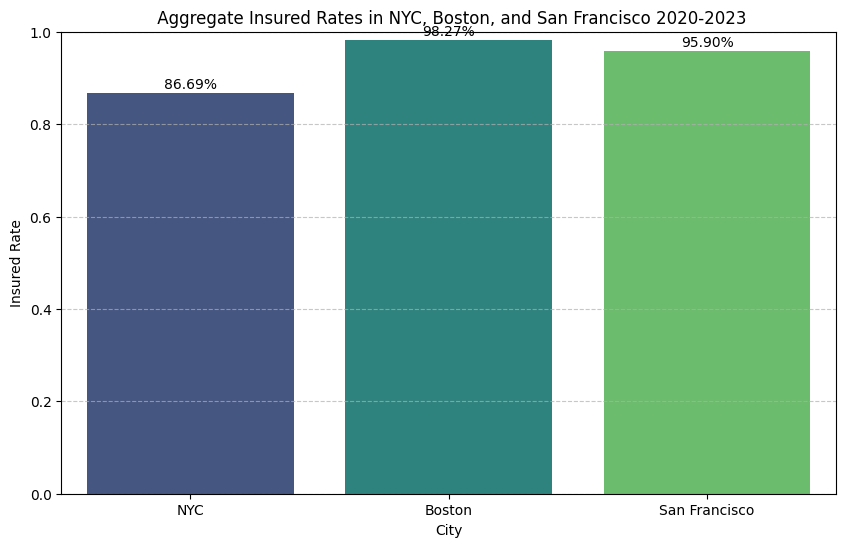

In [31]:
plt.figure(figsize=(10, 6))
sns.barplot(x='City', y='Insured_Rate', data=df_insured_rates, hue='City', palette='viridis', legend=False)
plt.title(' Aggregate Insured Rates in NYC, Boston, and San Francisco 2020-2023')
plt.xlabel('City')
plt.ylabel('Insured Rate')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, row in df_insured_rates.iterrows():
    plt.text(index, row.Insured_Rate + 0.01, f'{row.Insured_Rate:.2%}', color='black', ha="center")

plt.show()

In [32]:
os.listdir("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison")

['Health_Insurance_Data_Exploration',
 'NYC EH Data Portal - Health insurance (adults) (full table).xlsx',
 'health-equity-report-databook-region.xlsx',
 'NYC EH Data Portal - Health insurance (adults) (full table).xlsx - NYC EH Data Portal - Health ins.csv',
 'health-equity-report-databook-region.xlsx - 2.csv',
 '2023-MHIS-Detailed-Tables (1).xlsx',
 'city-dash-data.zip',
 'CityHealthDash-cities.csv',
 'Initial Data Exploration and Analysis _ Health Insurance Data Exploration.pdf',
 'Health Care Diversity.csv',
 'Health Care Diversity NYC Age.csv',
 'Health_Insurance_Data_Exploration.ipynb',
 'Health Care Diversity SF.csv',
 'Health Care Diversity Boston.csv',
 'Health Care Diversity NYC.csv',
 'Health Care Diversity Boston Age.csv',
 'Health Care Diversity SF Age.csv']

In [33]:

os.listdir("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison")
df_hcdivNYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity NYC.csv")
df_hcdivBOS = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity Boston.csv")
df_hcdivSF = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity SF.csv")
df_hcdivNYC.head()
df_hcdivBOS.head()
df_hcdivSF.head()




,Gender ID,Gender,Health Coverage ID,Health Coverage,Year,Health Insurance by Gender and Age,Share
0,0,Male,0,Private,2013,292997,50.765123
1,0,Male,0,Private,2014,298036,50.793250
2,0,Male,0,Private,2015,306333,50.869149
3,0,Male,0,Private,2016,315971,50.990616
4,0,Male,0,Private,2017,325277,51.149893


In [34]:

df_nyc_with_city = df_hcdivNYC.copy()
df_nyc_with_city['City'] = 'NYC'

df_boston_with_city = df_hcdivBOS.copy()
df_boston_with_city['City'] = 'Boston'

df_sf_with_city = df_hcdivSF.copy()
df_sf_with_city['City'] = 'San Francisco'

df_combined_hcdiv = pd.concat([df_nyc_with_city, df_boston_with_city, df_sf_with_city], ignore_index=True)

print("First 5 rows of df_combined_hcdiv:")
display(df_combined_hcdiv.head())

print("\nUnique values in 'Health Coverage' column:")
print(df_combined_hcdiv['Health Coverage'].unique())

print("\nUnique values in 'Gender' column:")
print(df_combined_hcdiv['Gender'].unique())



First 5 rows of df_combined_hcdiv:


,Gender ID,Gender,Health Coverage ID,Health Coverage,Year,Health Insurance by Gender and Age,Share,City
0,0,Male,0,Private,2013,2128767,47.194491,NYC
1,0,Male,0,Private,2014,2150068,47.381035,NYC
2,0,Male,0,Private,2015,2189390,47.601519,NYC
3,0,Male,0,Private,2016,2236772,47.730816,NYC
4,0,Male,0,Private,2017,2298022,47.777346,NYC



Unique values in 'Health Coverage' column:
['Private' 'Public']

Unique values in 'Gender' column:
['Male' 'Female']


In [35]:

df_filtered_years = df_combined_hcdiv[(df_combined_hcdiv['Year'] >= 2020) & (df_combined_hcdiv['Year'] <= 2023)]

df_private_coverage = df_filtered_years[df_filtered_years['Health Coverage'] == 'Private']
df_public_coverage = df_filtered_years[df_filtered_years['Health Coverage'] == 'Public']

print("First 5 rows of df_private_coverage:")
display(df_private_coverage.head())

print("\nFirst 5 rows of df_public_coverage:")
display(df_public_coverage.head())


First 5 rows of df_private_coverage:


,Gender ID,Gender,Health Coverage ID,Health Coverage,Year,Health Insurance by Gender and Age,Share,City
7,0,Male,0,Private,2020,2359355,47.967502,NYC
8,0,Male,0,Private,2021,2453674,48.136324,NYC
9,0,Male,0,Private,2022,2418265,48.344348,NYC
10,0,Male,0,Private,2023,2371948,48.209100,NYC
29,1,Female,0,Private,2020,2559298,52.032498,NYC



First 5 rows of df_public_coverage:


,Gender ID,Gender,Health Coverage ID,Health Coverage,Year,Health Insurance by Gender and Age,Share,City
18,0,Male,1,Public,2020,1609542,44.922884,NYC
19,0,Male,1,Public,2021,1719650,45.480248,NYC
20,0,Male,1,Public,2022,1733648,45.556128,NYC
21,0,Male,1,Public,2023,1750797,45.661975,NYC
40,1,Female,1,Public,2020,1973358,55.077116,NYC


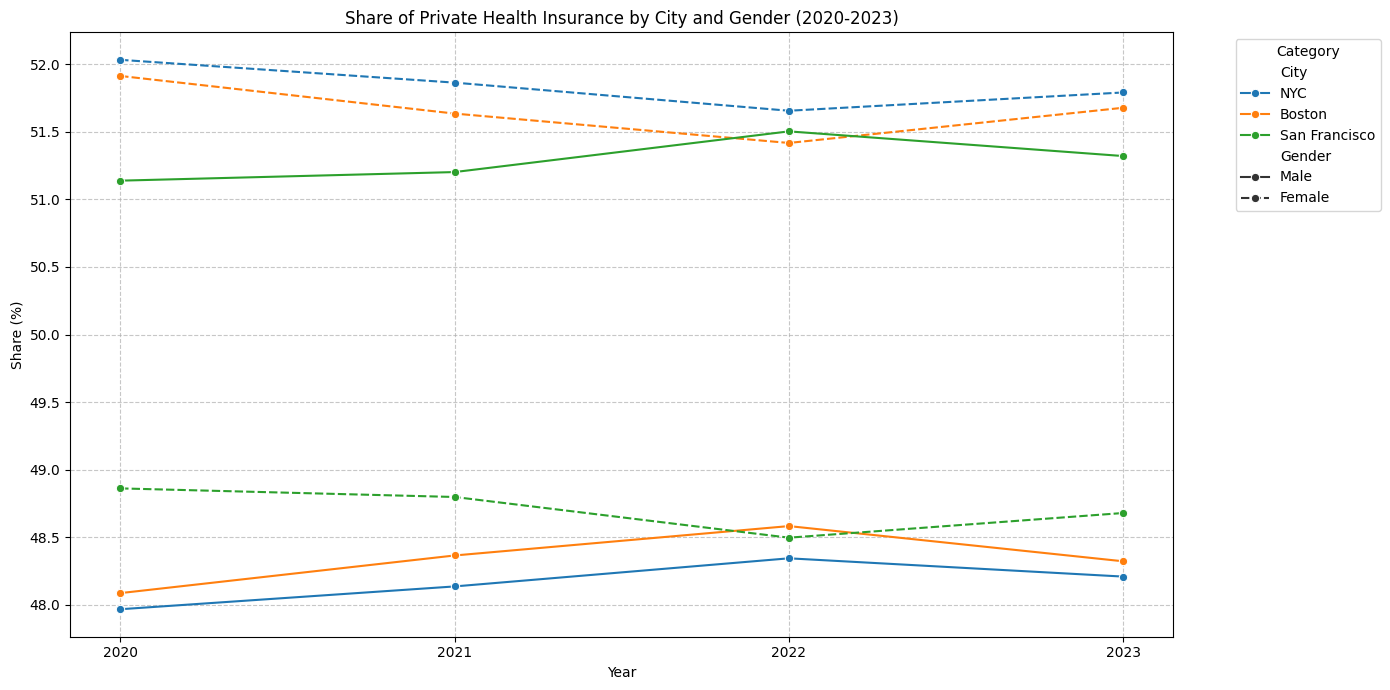

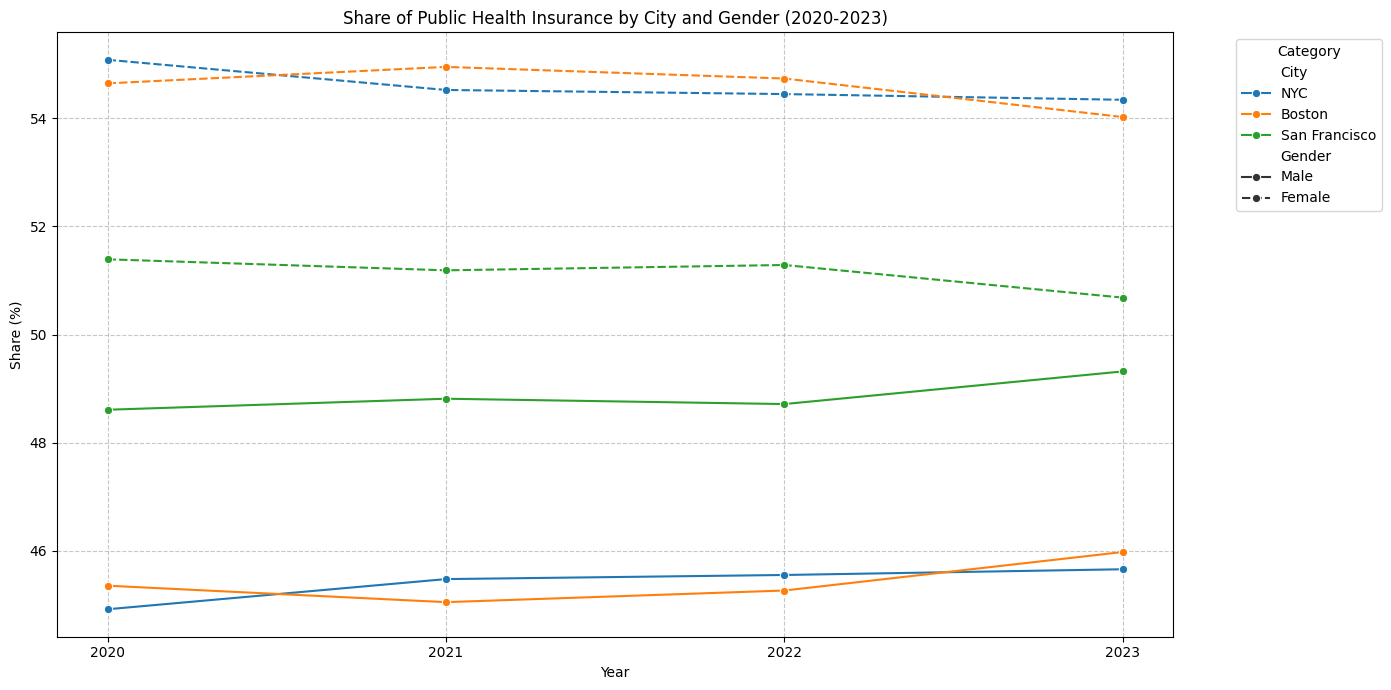

In [36]:

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_private_coverage, x='Year', y='Share', hue='City', style='Gender', marker='o')
plt.title('Share of Private Health Insurance by City and Gender (2020-2023)')
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.xticks(df_private_coverage['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_public_coverage, x='Year', y='Share', hue='City', style='Gender', marker='o')
plt.title('Share of Public Health Insurance by City and Gender (2020-2023)')
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.xticks(df_public_coverage['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [37]:

df_hcageNYC = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity NYC Age.csv")
df_hcageBoston = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity Boston Age.csv")
df_hcageSF = pd.read_csv("/content/drive/My Drive/CIS_9650_Group_Project/Health Insurance Comparison/Health Care Diversity SF Age.csv")


In [38]:

df_nyc_age_with_city = df_hcageNYC.copy()
df_nyc_age_with_city['City'] = 'NYC'

df_boston_age_with_city = df_hcageBoston.copy()
df_boston_age_with_city['City'] = 'Boston'

df_sf_age_with_city = df_hcageSF.copy()
df_sf_age_with_city['City'] = 'San Francisco'

df_combined_hcage = pd.concat([df_nyc_age_with_city, df_boston_age_with_city, df_sf_age_with_city], ignore_index=True)

print("First 5 rows of df_combined_hcage:")
display(df_combined_hcage.head())


First 5 rows of df_combined_hcage:


,Age ID,Age,Kaiser Coverage ID,Kaiser Coverage,Year,Health Insurance Policies,Share,City
0,0,Under 18 Years,0,Medicaid,2013,822940.0,37.860204,NYC
1,0,Under 18 Years,0,Medicaid,2014,838671.0,37.178478,NYC
2,0,Under 18 Years,0,Medicaid,2015,851211.0,36.404293,NYC
3,0,Under 18 Years,0,Medicaid,2016,851818.0,35.625269,NYC
4,0,Under 18 Years,0,Medicaid,2017,880236.0,36.027465,NYC


In [39]:

df_combined_hcage['Insured Share'] = 100 - df_combined_hcage['Share']

print("First 5 rows of df_combined_hcage with 'Insured Share':")
display(df_combined_hcage.head())


First 5 rows of df_combined_hcage with 'Insured Share':


,Age ID,Age,Kaiser Coverage ID,Kaiser Coverage,Year,Health Insurance Policies,Share,City,Insured Share
0,0,Under 18 Years,0,Medicaid,2013,822940.0,37.860204,NYC,62.139796
1,0,Under 18 Years,0,Medicaid,2014,838671.0,37.178478,NYC,62.821522
2,0,Under 18 Years,0,Medicaid,2015,851211.0,36.404293,NYC,63.595707
3,0,Under 18 Years,0,Medicaid,2016,851818.0,35.625269,NYC,64.374731
4,0,Under 18 Years,0,Medicaid,2017,880236.0,36.027465,NYC,63.972535


In [40]:

df_uninsured_filtered = df_combined_hcage[(df_combined_hcage['Year'] >= 2020) & (df_combined_hcage['Year'] <= 2023)]

print("First 5 rows of df_uninsured_filtered:")
display(df_uninsured_filtered.head())


First 5 rows of df_uninsured_filtered:


,Age ID,Age,Kaiser Coverage ID,Kaiser Coverage,Year,Health Insurance Policies,Share,City,Insured Share
7,0,Under 18 Years,0,Medicaid,2020,817656.0000,34.243972,NYC,65.756028
8,0,Under 18 Years,0,Medicaid,2021,861946.0000,34.197150,NYC,65.802850
9,0,Under 18 Years,0,Medicaid,2022,853025.9375,33.692563,NYC,66.307437
10,0,Under 18 Years,0,Medicaid,2023,844577.0000,33.286682,NYC,66.713318
18,0,Under 18 Years,1,Medicare,2020,3155.0000,0.414288,NYC,99.585712


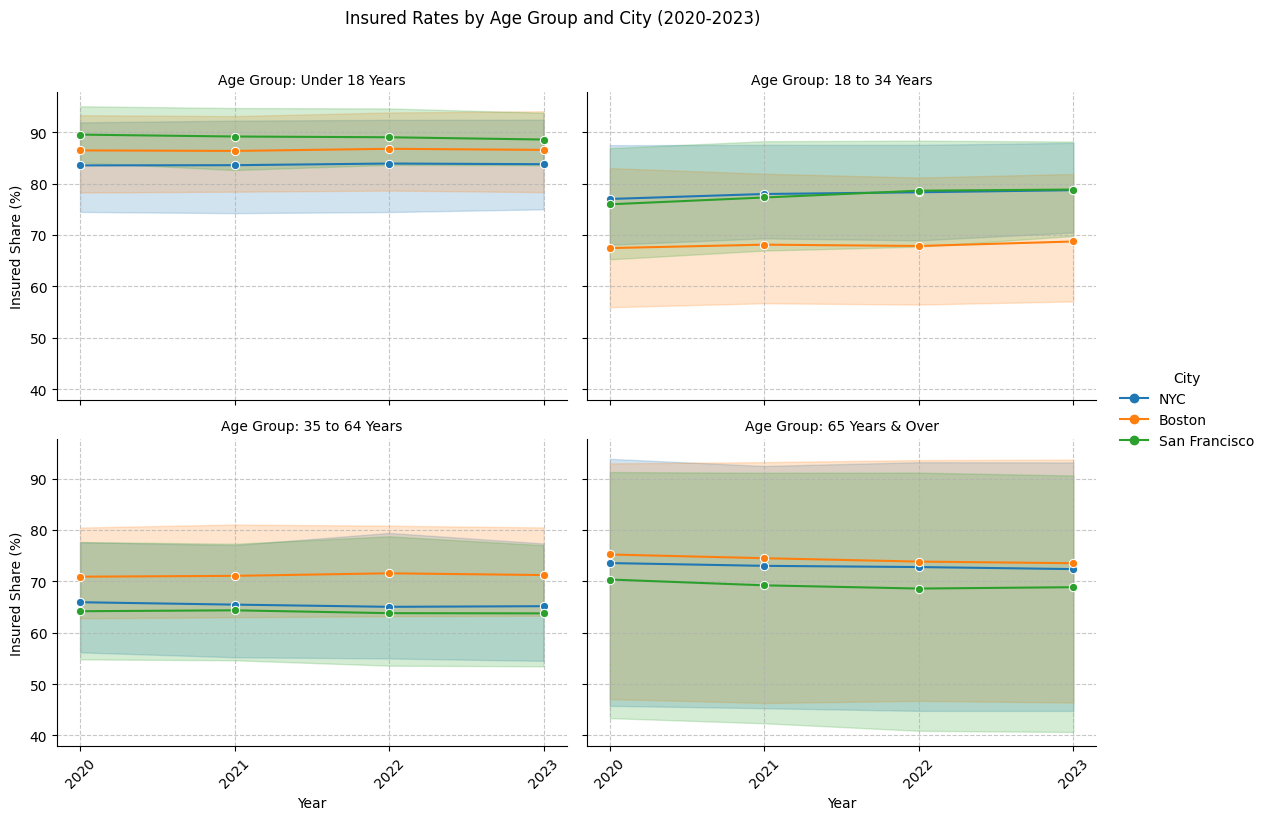

In [41]:

g = sns.relplot(
    data=df_uninsured_filtered,
    x='Year',
    y='Insured Share',
    col='Age',
    hue='City',
    kind='line',
    marker='o',
    col_wrap=2, # Wrap columns after 2 plots for better layout
    height=4,
    aspect=1.2
)
g.fig.suptitle('Insured Rates by Age Group and City (2020-2023)', y=1.02) # Adjust title position
g.set_axis_labels('Year', 'Insured Share (%)')
g.set_titles('Age Group: {col_name}')
g.add_legend(bbox_to_anchor=(1.12, 1), loc='upper left', borderaxespad=0)

for ax in g.axes.flat:
    ax.set_xticks(df_uninsured_filtered['Year'].unique())
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 5. Economic Stability: Income vs. Housing Costs
**Objective:** High income does not always equate to high affordability. This section contrasts the Median Household Income (from ACS data) against Median Housing Prices (from Zillow) for 2023. We calculate the "Price-to-Income Ratio" to determine which city poses the greatest financial burden on its residents.

In [42]:

nyc_income = pd.read_csv('/content/drive/My Drive/CIS_9650_Group_Project/Income vs Housing/nyc_Income.csv')
sf_income = pd.read_csv('/content/drive/My Drive/CIS_9650_Group_Project/Income vs Housing/sf_Income.csv')
bos_income = pd.read_csv('/content/drive/My Drive/CIS_9650_Group_Project/Income vs Housing/bos_Income.csv')
zillow_df = pd.read_excel('/content/drive/My Drive/CIS_9650_Group_Project/Income vs Housing/Zillow_Metro_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.xlsx')

sf_income.head(), bos_income.head(), zillow_df.head()


(  Place Place-Tract ID  Place Place-Tract      Place-Tract ID  \
 0       16000US0667000  San Francisco, CA  14000US06075010100   
 1       16000US0667000  San Francisco, CA  14000US06075010100   
 2       16000US0667000  San Francisco, CA  14000US06075010100   
 3       16000US0667000  San Francisco, CA  14000US06075010100   
 4       16000US0667000  San Francisco, CA  14000US06075010100   
 
                                   Place-Tract  Race ID   Race  Year  \
 0  Census Tract 101, San Francisco County, CA        0  Total  2013   
 1  Census Tract 101, San Francisco County, CA        0  Total  2014   
 2  Census Tract 101, San Francisco County, CA        0  Total  2015   
 3  Census Tract 101, San Francisco County, CA        0  Total  2016   
 4  Census Tract 101, San Francisco County, CA        0  Total  2017   
 
    Household Income by Race  Household Income by Race Moe  
 0                   54798.0                       24445.0  
 1                   75725.0                  

In [43]:
nyc_income.shape

(23313, 9)

In [44]:
zillow_df.head(10)

,RegionID,SizeRank,RegionName,RegionType,StateName,2000-01-31 00:00:00,2000-02-29 00:00:00,2000-03-31 00:00:00,2000-04-30 00:00:00,2000-05-31 00:00:00,...,2024-12-31 00:00:00,2025-01-31 00:00:00,2025-02-28 00:00:00,2025-03-31 00:00:00,2025-04-30 00:00:00,2025-05-31 00:00:00,2025-06-30 00:00:00,2025-07-31 00:00:00,2025-08-31 00:00:00,2025-09-30 00:00:00
0,102001,0,United States,country,NaN,123328.165417,123545.139196,123814.218630,124391.341197,125055.540080,...,365372.217349,366007.694288,366471.281294,366193.660206,365661.222907,364970.033287,364347.749809,363917.639079,363688.149053,363931.687425
1,394913,1,"New York, NY",msa,NY,222096.674116,223040.459669,223992.986378,225923.174072,227921.950272,...,696533.300128,697633.014562,698948.623497,700676.336950,703154.623667,704955.084297,706457.122100,707650.653457,708454.797763,709880.464236
2,753899,2,"Los Angeles, CA",msa,CA,222620.175787,223448.605299,224552.065508,226747.580645,229148.785908,...,968173.703124,968714.163371,966675.169598,961554.657443,957217.264182,952421.630548,948047.015396,945442.656758,944366.276929,945428.022538
3,394463,3,"Chicago, IL",msa,IL,155857.310945,156001.589412,156276.370294,156959.956841,157782.229234,...,332649.038316,334015.386374,335383.265039,336242.517133,336852.936258,337148.112023,337514.741114,338367.259828,339378.680707,340732.680569
4,394514,4,"Dallas, TX",msa,TX,128023.642757,128080.664935,128146.217766,128316.451582,128540.900207,...,377150.293426,376619.688458,375829.848426,374322.685671,372189.097900,369765.587859,367394.345281,365371.532830,364005.278732,363356.229199
5,394692,5,"Houston, TX",msa,TX,124078.051110,124101.163041,124014.530927,124066.314475,124114.083139,...,312161.571325,312100.905058,311952.268205,311309.567281,310386.496438,309439.943725,308449.444144,307608.784662,306893.756443,306424.516925
6,395209,6,"Washington, DC",msa,VA,181789.446935,181937.255843,182209.677442,182826.518246,183764.221130,...,576487.512710,578084.047234,579224.114592,579283.557949,579001.591575,577799.873649,576501.674784,575489.669391,574941.658173,574999.395441
7,394974,7,"Philadelphia, PA",msa,PA,123156.391394,123430.121948,123616.932154,124077.905551,124523.992661,...,371855.641952,372981.718540,374078.295657,374776.794814,375642.274391,376578.521273,377489.751300,378524.046085,379286.277932,380103.710119
8,394856,8,"Miami, FL",msa,FL,114286.964041,114600.705697,114932.941987,115604.131645,116253.649839,...,493058.102297,492437.701635,491687.685071,489717.117011,487087.116862,483857.575187,480647.952545,477076.633959,474123.548095,472130.339380
9,394347,9,"Atlanta, GA",msa,GA,149137.866095,149481.603311,149886.589383,150747.950043,151710.241012,...,391103.131475,390278.491245,389426.545551,388081.167361,386703.503535,385168.175170,383803.984405,382514.585059,381649.445866,381270.625317


In [45]:
#extra 2023 income
sf_2023 = sf_income[(sf_income['Year'] == 2023) & (sf_income['Race'] == 'Total')]
bos_2023 = bos_income[(bos_income['Year'] == 2023) & (bos_income['Race'] == 'Total')]
nyc_2023 = nyc_income[(nyc_income['Year'] == 2023) & (nyc_income['Race'] == 'Total')]



In [46]:
#median income for three cities
sf_median = sf_2023['Household Income by Race'].median()
bos_median = bos_2023['Household Income by Race'].median()
nyc_median = nyc_2023['Household Income by Race'].median()

sf_median, bos_median, nyc_median


(143531.0, 92560.0, 82037.5)

In [47]:
#summary median datafram
city_income_2023 = pd.DataFrame({
    "City": ["New York City", "Boston", "San Francisco"],
    "Median_Income_2023": [82037.5, 92560.0, 143531.0]
})

city_income_2023

,City,Median_Income_2023
0,New York City,82037.5
1,Boston,92560.0
2,San Francisco,143531.0


In [48]:
# Select all date-like columns
date_cols = [c for c in zillow_df.columns
             if isinstance(c, str) and c[:4].isdigit()]

# Select only 2023 columns
cols_2023 = [c for c in date_cols if c.startswith("2023")]

print("Columns from year 2023:", cols_2023)

Columns from year 2023: []


In [49]:
# New York related rows from zillow_df
z_ny = zillow_df[zillow_df["RegionName"].str.contains("New York", case=False, na=False)]
print("New York related regions:")
print(z_ny[["RegionName"]].head(10))

# Boston related rows from zillow_df
z_bos = zillow_df[zillow_df["RegionName"].str.contains("Boston", case=False, na=False)]
print("\nBoston related regions:")
print(z_bos[["RegionName"]].head(10))

# San Francisco related rows from zillow_df
z_sf = zillow_df[zillow_df["RegionName"].str.contains("San Francisco", case=False, na=False)]
print("\nSan Francisco related regions:")
print(z_sf[["RegionName"]].head(10))


New York related regions:
     RegionName
1  New York, NY

Boston related regions:
    RegionName
10  Boston, MA

San Francisco related regions:
           RegionName
12  San Francisco, CA


In [50]:
# New York
ny_row = z_ny.iloc[0]
ny_median_2023 = ny_row[cols_2023].median()
print("NYC median housing price 2023:", ny_median_2023)

# Boston
bos_row = z_bos.iloc[0]
bos_median_2023 = bos_row[cols_2023].median()
print("Boston median housing price 2023:", bos_median_2023)

# San Francisco
sf_row = z_sf.iloc[0]
sf_median_2023 = sf_row[cols_2023].median()
print("SF median housing price 2023:", sf_median_2023)


NYC median housing price 2023: nan
Boston median housing price 2023: nan
SF median housing price 2023: nan


In [51]:
housing_2023 = pd.DataFrame({
    "City": ["New York City", "Boston", "San Francisco"],
    "Median_Housing_2023": [634912.43,
                            656954.84,
                            1100417.44]
})

print(housing_2023)


            City  Median_Housing_2023
0  New York City            634912.43
1         Boston            656954.84
2  San Francisco           1100417.44


In [52]:
#combine miedian income and median housing
merged_2023 = city_income_2023.merge(
    housing_2023,
    on="City",
    how="inner"
)

merged_2023["Price_to_Income"] = (
    merged_2023["Median_Housing_2023"] / merged_2023["Median_Income_2023"]
)

print(merged_2023)



            City  Median_Income_2023  Median_Housing_2023  Price_to_Income
0  New York City             82037.5            634912.43         7.739295
1         Boston             92560.0            656954.84         7.097611
2  San Francisco            143531.0           1100417.44         7.666758


/tmp/ipython-input-1253463247.py:52: UserWarning: Legend does not support handles for Text instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax1.legend(loc="upper left")


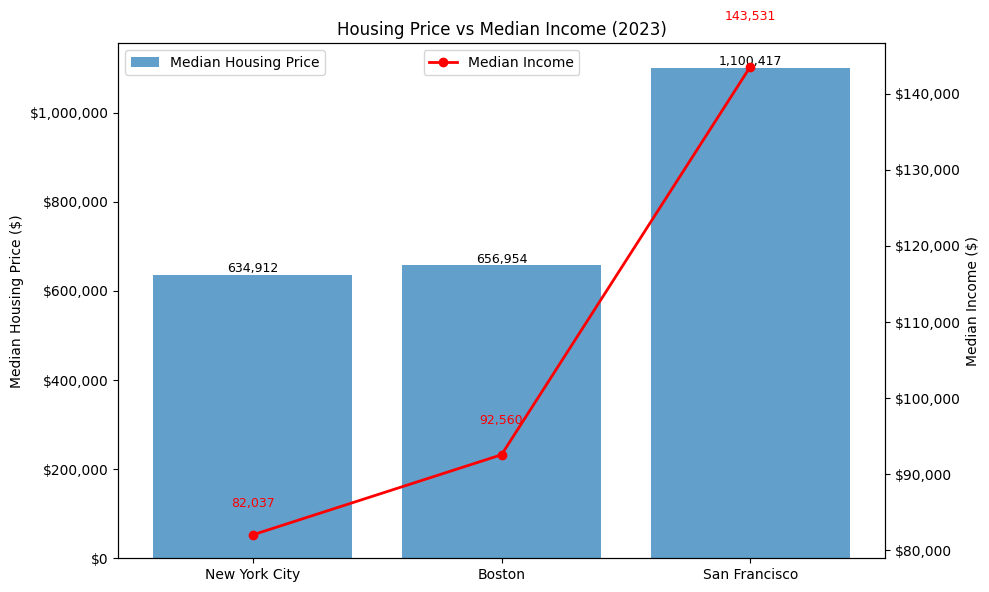

In [53]:
#visualization
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis → Housing (bar)
bars = ax1.bar(merged_2023["City"],
        merged_2023["Median_Housing_2023"],
        label="Median Housing Price",
        alpha=0.7,
        )

ax1.set_ylabel("Median Housing Price ($)")
ax1.set_title("Housing Price vs Median Income (2023)")

# Add value labels for bars
for bar in bars:
        height = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=9,
            label = "Median Housing Price"
        )
# Right axis → Income (line)
ax2 = ax1.twinx()
ax2.plot(merged_2023["City"],
         merged_2023["Median_Income_2023"],
         color="red",
         marker="o",
         linewidth=2,
         label="Median Income")

ax2.set_ylabel("Median Income ($)")
# Add value labels for line points
for x, y in zip(merged_2023["City"], merged_2023["Median_Income_2023"]):
          ax2.text(
              x,
              y + (y * 0.04),
              f"{int(y):,}",
              ha="center",
              va="bottom",
              fontsize=9,
              color="red"
          )
import matplotlib.ticker as mtick

ax1.yaxis.set_major_formatter(mtick. StrMethodFormatter('${x:,.0f}'))
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

ax1.legend(loc="upper left")
ax2.legend(loc="upper center")

fig.tight_layout()
plt.show()


## 6. Educational Attainment
**Objective:** Education levels often correlate with economic opportunity and city growth. In this final analysis, we compare the percentage of the population (aged 25+) holding a **Bachelor's Degree or Higher** in Boston versus New York City.

*Note: We calculate a population-weighted average for NYC to account for its diverse boroughs, ensuring a fair comparison against Boston's city-level data.*

--- 4. Education Analysis ---

[EDA] Boston Education Data Sample:
Shape: (29, 29)


,United States,220622076,26472261,0.119989,50745827,0.230012,8726921,0.039556,45044698,0.204171,...,26472261.1,0.11998917551659699.1,59472748,0.269568,63756905,0.288987,43646104.1,0.19783198849058062.1,27274058.1,0.12362343104776151.1
0,Massachusetts,4781683.0,441944.0,0.092424,1014308.0,0.212124,134217.0,0.028069,738484.0,0.154440,...,441944.0,0.092424,1148525.0,0.240193,1102149.0,0.230494,1151870.0,0.240892,937195.0,0.195997
1,Boston,473775.0,60508.0,0.127715,80223.0,0.169327,13163.0,0.027783,62266.0,0.131425,...,60508.0,0.127715,93386.0,0.197110,84255.0,0.177838,128045.0,0.270265,107581.0,0.227072
2,Allston,10432.0,571.0,0.054735,701.0,0.067197,72.0,0.006902,886.0,0.084931,...,571.0,0.054735,773.0,0.074099,1244.0,0.119248,4338.0,0.415836,3506.0,0.336081
3,Back Bay,13791.0,284.0,0.020593,565.0,0.040969,31.0,0.002248,690.0,0.050033,...,284.0,0.020593,596.0,0.043217,1130.0,0.081937,5396.0,0.391270,6385.0,0.462983
4,Beacon Hill,8203.0,169.0,0.020602,148.0,0.018042,20.0,0.002438,270.0,0.032915,...,169.0,0.020602,168.0,0.020480,399.0,0.048641,3815.0,0.465074,3652.0,0.445203
5,Brighton,39650.0,2660.0,0.067087,3968.0,0.100076,709.0,0.017881,4149.0,0.104641,...,2660.0,0.067087,4677.0,0.117957,5477.0,0.138134,15575.0,0.392812,11261.0,0.284010
6,Charlestown,15069.0,1192.0,0.079103,1833.0,0.121640,229.0,0.015197,1243.0,0.082487,...,1192.0,0.079103,2062.0,0.136837,1656.0,0.109894,4987.0,0.330944,5172.0,0.343221
7,Dorchester,86012.0,15449.0,0.179614,22117.0,0.257139,3580.0,0.041622,14716.0,0.171092,...,15449.0,0.179614,25697.0,0.298761,19657.0,0.228538,16095.0,0.187125,9114.0,0.105962
8,Downtown,12722.0,1963.0,0.154300,1123.0,0.088272,222.0,0.017450,877.0,0.068936,...,1963.0,0.154300,1345.0,0.105722,1399.0,0.109967,3327.0,0.261515,4688.0,0.368496
9,East Boston,33947.0,9228.0,0.271836,8883.0,0.261673,842.0,0.024803,3900.0,0.114885,...,9228.0,0.271836,9725.0,0.286476,5182.0,0.152650,6413.0,0.188912,3399.0,0.100127



Calculated Percentages:
            City  Bachelor Degree %
0  New York City          32.141554
1         Boston          49.733734
2  San Francisco          60.120764


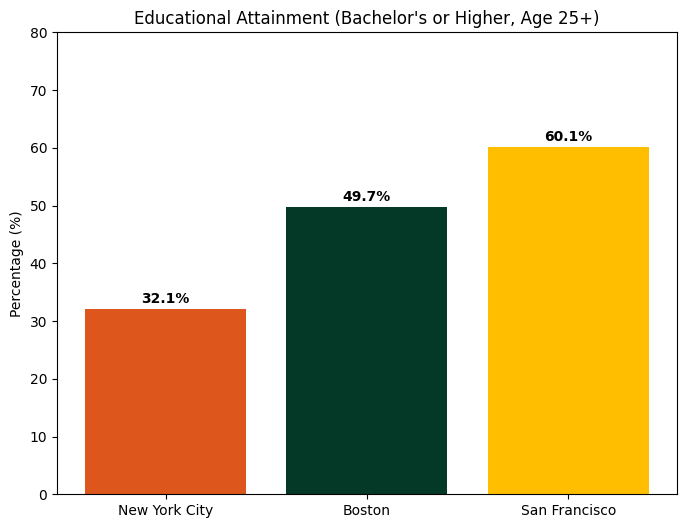

In [54]:
# --- PART 4: EDUCATIONAL ATTAINMENT ---
print("--- 4. Education Analysis ---")

base_path = '/content/drive/MyDrive/CIS_9650_Group_Project'
db_folder = os.path.join(base_path,"Databases")

# 1. Boston Analysis (Excel)
file_bos = os.path.join(db_folder, 'Boston.xlsm')
df_bos_edu = pd.read_excel(file_bos, sheet_name="Educational Attainment", header=3)

# --- RUBRIC REQUIREMENT: Exploratory Data Analysis (EDA) ---
print("\n[EDA] Boston Education Data Sample:")
print(f"Shape: {df_bos_edu.shape}")
display(df_bos_edu.head(10))
# -----------------------------------------------------------

# Filter for the row "Boston"
bos_row = df_bos_edu[df_bos_edu.iloc[:, 0].str.strip() == "Boston"].iloc[0]

# Index 13 is Bachelor's %, Index 15 is Master's/Professional %
bos_pct = (bos_row.iloc[13] + bos_row.iloc[15]) * 100

# 2. NYC Analysis (CSV)
file_nyc = os.path.join(db_folder, 'nyc_EDUCATIONAL ATTAINMENT08-12.xlsx - ACS_12_5YR_DP02.csv')
df_nyc_edu = pd.read_csv(file_nyc, encoding="latin1")

# Find rows for Population and Percentage
col_label = df_nyc_edu.columns[0]
row_pop = df_nyc_edu[df_nyc_edu[col_label].str.contains("Population 25 years and over", na=False)].iloc[0]
row_pct = df_nyc_edu[df_nyc_edu[col_label].str.contains("Percent bachelor's degree or higher", na=False)].iloc[0]

# Clean data: Drop NaNs to avoid "zero" errors from missing data
def clean_and_align(pop_row, pct_row):
    # Convert to numeric, forcing errors to NaN
    p = pd.to_numeric(pop_row[1:], errors='coerce')
    c = pd.to_numeric(pct_row[1:], errors='coerce')
    # Combine and drop rows where either is NaN
    df = pd.DataFrame({'pop': p, 'pct': c}).dropna()
    return df['pop'].values, df['pct'].values

pops, pcts = clean_and_align(row_pop, row_pct)

# Weighted Average for NYC
nyc_weighted_sum = np.sum(pops * (pcts / 100))
nyc_total_pop = np.sum(pops)
nyc_pct = (nyc_weighted_sum / nyc_total_pop) * 100

# 3. San Francisco Analysis (New CSV)
file_sf = os.path.join(db_folder, 'sf_education_ACS_2023.csv')
df_sf_edu = pd.read_csv(file_sf)

# The data is in row index 1 (the 3rd line of the CSV)
# Column 'S1501_C01_006E' is Total Population 25+
# Column 'S1501_C01_015E' is Bachelor's degree or higher count
sf_data = df_sf_edu.iloc[1]
sf_total = float(sf_data['S1501_C01_006E'])
sf_bach = float(sf_data['S1501_C01_015E'])

sf_pct = (sf_bach / sf_total) * 100

# 4. Plot Results
edu_df = pd.DataFrame({
    'City': ['New York City', 'Boston', 'San Francisco'],
    'Bachelor Degree %': [nyc_pct, bos_pct, sf_pct]
})

print("\nCalculated Percentages:")
print(edu_df)

plt.figure(figsize=(8, 6))
bars = plt.bar(edu_df['City'], edu_df['Bachelor Degree %'], color=['#DD571C', '#043927', '#FFBF00'])
plt.title("Educational Attainment (Bachelor's or Higher, Age 25+)")
plt.ylabel("Percentage (%)")
plt.ylim(0, 80)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1, f"{height:.1f}%", ha='center', fontweight='bold')

plt.show()

## 7. Conclusion
Through this multi-faceted analysis, we observe distinct trade-offs between these major cities:

1.  **Commute:** NYC relies heavily on public transit, while other cities show higher reliance on driving, reflecting NYC's density and infrastructure.
2.  **Economy:** San Francisco offers the highest median income but comes with the steepest housing costs (Price-to-Income ratio ~7.6). Boston appears slightly more balanced (Ratio ~7.1) compared to NYC (Ratio ~7.7), which has the lowest median income of the three despite high costs.
3.  **Education:** Boston significantly outperforms the NYC aggregate in higher education attainment (approx. 50% vs 32%), likely driven by its high concentration of universities.

This data suggests that while NYC offers robust infrastructure (transit), it faces significant challenges in affordability and economic balance compared to Boston and San Francisco.